# Virtual Attendance: taking the register with a face

**The question:** the legacy script turns a webcam into a class register. It encodes one photograph of each student, shrinks every camera frame to a quarter of its size, finds the faces, compares each with the students, writes the name of the nearest student into a CSV file if the match is within the library's default tolerance, and never marks anybody twice. It looks great in a demo with five people on a desk. *But how good is the register in a real class? Does accuracy fall as the roster grows? Do more enrolment photographs help? What happens when a stranger walks in, who is "nearest" to somebody whatever they look like? And what does the quarter-size shrink cost?* We build a **simulation on real photographs: Labeled Faces in the Wild (13,233 photographs of 5,749 people)**, where we know who is who, and measure the register itself: who gets marked present who should not be.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the people and the photographs
4. Hypotheses and why we chose each test
5. Describing a face
6. H1: does the class size matter?
7. H2: do more enrolment photographs help?
8. H3: what about strangers?
9. H4: what does standing further back cost?
10. H5: the attendance sheet
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab CV/virtual-attendance/virtual_attendance.ipynb`, or *Run All* in any Jupyter. LFW (about 180 MB) and two small models (about 40 MB) download themselves on the first run. It takes about 10 minutes on a CPU.

## 1. 💡 The simple analogy

Imagine a **teacher taking the register by recognising faces**, with a glance at each student as they come in.

- With **10 students** it is easy; with **250** there are more look-alikes, and the nearest face is more often the wrong one.
- The teacher met each student **once** (one enrolment photograph). If she had seen each three times, she would know them better.
- A **stranger** walks in. A teacher who *must* name someone will pick the student who looks most like the stranger; a better teacher says "I don't know you" when nobody looks close enough. The **threshold of "close enough"** is the whole difference.
- If the class sits **at the back of the room**, every face is small and the teacher gets less sure.
- A careful teacher also **looks twice**: she marks a student present only if she recognises them in two of three glances.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the roster sizes, the number of random rosters per setting (30) and the number of simulated classes (300) keeps the notebook reproducible and avoids "magic numbers". Every random roster has its own fixed seed, so every run gives the same numbers.

In [1]:
import contextlib
import os
import sys
import tarfile
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
SFACE_THRESHOLD = 0.363  # cosine similarity threshold recommended with the SFace model
DETECT_SCORE = 0.5
MIN_PHOTOS = 6  # people with at least this many photographs can be on a class roster
N_DRAWS = 30  # random rosters per setting
N_VISITS = 5  # visits (photographs) per student in the closed-set tests
SCALES = [1.0, 0.5, 0.25]  # how large the scene is in the frame (1 = as photographed)
N_SESSIONS = 300
URLS = {
    "lfw.tgz": "https://ndownloader.figshare.com/files/5976018",
    "face_detection_yunet_2023mar.onnx": "https://github.com/opencv/opencv_zoo/raw/main/models/"
    "face_detection_yunet/face_detection_yunet_2023mar.onnx",
    "face_recognition_sface_2021dec.onnx": "https://github.com/opencv/opencv_zoo/raw/main/models/"
    "face_recognition_sface/face_recognition_sface_2021dec.onnx",
}
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


@contextlib.contextmanager
def silence_native_logs():
    """Hides messages that compiled libraries write straight to the terminal (file descriptor 2)."""
    sys.stderr.flush()
    saved, devnull = os.dup(2), os.open(os.devnull, os.O_WRONLY)
    os.dup2(devnull, 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(devnull)
        os.close(saved)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the people and the photographs

*What:* LFW: 13,233 photographs of 5,749 people. To put somebody on a roster we need an **enrolment photograph and later visits**, so only people with at least **6 photographs** are eligible as students; everybody else can be a **guest** that the register must not accept. We count how many people have how many photographs. *Why:* the benchmark decides what the simulation can say: LFW is made of public figures with many photographs, not of ordinary students.

> **Problems in the legacy script this replaces:** it needs a live webcam and a folder of photographs named after people, so nothing can be measured; it shrinks every frame by a factor of **4** before looking for faces, which turns a 150-pixel face into a 37-pixel one; it compares each face with the roster and accepts the nearest one if it is within the library's default tolerance, with **no control of how many strangers get in**; it indexes `face_encodings(img)[0]`, which crashes on a photograph with no face; and its register rule (one accepted frame marks a student) means a single wrong frame is a wrong entry.

In [2]:
for name, url in URLS.items():
    target = DATA_DIR / name
    if not target.exists():
        request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=300) as response:
            target.write_bytes(response.read())
if not (DATA_DIR / "lfw").exists():
    with tarfile.open(DATA_DIR / "lfw.tgz") as tf:
        tf.extractall(DATA_DIR, filter="data")

photos = sorted(DATA_DIR.glob("lfw/*/*.jpg"))
owner = np.array([p.parent.name for p in photos])
people, first, counts = np.unique(owner, return_index=True, return_counts=True)
by_person = {name: np.flatnonzero(owner == name) for name in people}
eligible = [n for n in people if len(by_person[n]) >= MIN_PHOTOS]
print(f"{len(photos):,} photographs of {len(people):,} people")
print(
    "People with at least 2 / 5 / 6 / 10 / 20 photographs: "
    + " / ".join(str(int((counts >= k).sum())) for k in (2, 5, 6, 10, 20))
)
print(
    f"{len(eligible)} people have at least {MIN_PHOTOS} photographs and can be put on a "
    f"roster; the other {len(people) - len(eligible):,} people are the 'guests' nobody "
    "enrolled"
)
print(
    f"People with a single photograph: {int((counts == 1).sum()):,} "
    f"({(counts == 1).mean():.0%} of the people, {(counts == 1).sum() / len(photos):.0%} of "
    "the photographs)"
)
print(
    f"Most photographed person: {people[counts.argmax()].replace('_', ' ')} "
    f"({counts.max()} photographs)"
)

13,233 photographs of 5,749 people
People with at least 2 / 5 / 6 / 10 / 20 photographs: 1680 / 423 / 311 / 158 / 62
311 people have at least 6 photographs and can be put on a roster; the other 5,438 people are the 'guests' nobody enrolled
People with a single photograph: 4,069 (71% of the people, 31% of the photographs)
Most photographed person: George W Bush (530 photographs)


**How to read this:**

- **13,233 photographs of 5,749 people, but very uneven:** **71%** of the people (4,069) have a single photograph (31% of all photographs); only **311** people have at least 6 photographs, and 62 have 20 or more. The most photographed person, George W Bush, has **530**.
- **So the student pool is the 311 most photographed people.** The other **5,438** people are the strangers the register must not accept.
- **A reminder about what this is:** public figures photographed by news agencies, not students on a webcam. Accuracy here is an optimistic ceiling.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does the roster size change the accuracy of "nearest student wins"? | Same accuracy at every size | Falls as the roster grows | 30 random rosters at each of 4 sizes; Kruskal-Wallis; regression on log roster size |
| H2 | Do more enrolment photographs help? | Same accuracy | Better with more | Same 30 rosters with 1, 3 and 5 photographs; paired Wilcoxon |
| H3 | Does "accept the nearest student" let strangers in, and does a threshold fix it? | Strangers are rejected | Many are accepted | Identification rate against false accept rate; a threshold chosen on separate rosters, tested on new ones |
| H4 | Does standing further from the camera cost accuracy? | Same | Lower | Same rosters at three distances; paired Wilcoxon |
| H5 | Does a careful rule (a tuned threshold and 2 of 3 frames) give a better register than the legacy rule? | Same errors | Fewer | 300 simulated classes; paired Wilcoxon |

*Why these tests?* Each random roster gives one number per setting; settings are compared on the **same rosters**, so the **paired Wilcoxon test**, which uses ranks, is the safe choice for percentages near 100%. The **false accept rate** (strangers let in) and the **identification rate** (students correctly named) are the two numbers that describe any recognition threshold. Choosing the threshold on 30 calibration rosters and judging it on 30 different ones avoids grading our own homework.

## 5. Describing a face

*What:* the same two models as in the face-recognition notebook: OpenCV's **YuNet** finds the face closest to the middle of the photograph, and **SFace** turns the aligned face into 128 numbers. Two faces are compared with the **cosine similarity** of their descriptions (near 1 is very alike). A student's **template** is the average description of their enrolment photographs. We describe every photograph at three scales: full size, a half and a quarter (the scene shrunk inside the frame, as if the person stood further away), keeping the width of the face in pixels. *Why:* a register compares a visitor with a template; shrinking tests the legacy "divide the frame by 4" step.

In [3]:
with silence_native_logs():
    detector = cv2.FaceDetectorYN.create(
        str(DATA_DIR / "face_detection_yunet_2023mar.onnx"),
        "",
        (250, 250),
        score_threshold=DETECT_SCORE,
    )
    recognizer = cv2.FaceRecognizerSF.create(
        str(DATA_DIR / "face_recognition_sface_2021dec.onnx"), ""
    )


def embed(image: np.ndarray, scale: float = 1.0) -> tuple[np.ndarray | None, float]:
    """Finds the most central face in a photograph and returns its identity embedding.

    Args:
        image: BGR photograph.
        scale: The scene is shrunk by this factor first (a person standing further away).

    Returns:
        The unit-length 128-number SFace embedding (None if no face is found) and the width of
        the detected face in pixels (0 if none).
    """
    if scale != 1.0:
        image = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    height, width = image.shape[:2]
    detector.setInputSize((width, height))
    _, faces = detector.detect(image)
    if faces is None or len(faces) == 0:
        return None, 0.0
    centre = np.array([width / 2, height / 2])
    face = min(faces, key=lambda f: np.linalg.norm(f[:2] + f[2:4] / 2 - centre))
    vector = recognizer.feature(recognizer.alignCrop(image, face)).ravel()
    return vector / np.linalg.norm(vector), float(face[2])


embeddings, widths = {}, {}
with silence_native_logs():
    for scale in SCALES:
        found = [embed(cv2.imread(str(p)), scale) for p in photos]
        embeddings[scale] = np.stack(
            [f[0] if f[0] is not None else np.full(128, np.nan, np.float32) for f in found]
        )
        widths[scale] = np.array([f[1] for f in found])
for scale in SCALES:
    seen = ~np.isnan(embeddings[scale][:, 0])
    print(
        f"Scale {scale}: a face is found in {seen.mean():.2%} of the photographs "
        f"(median face width {np.median(widths[scale][seen]):.0f} px)"
    )

Scale 1.0: a face is found in 100.00% of the photographs (median face width 93 px)
Scale 0.5: a face is found in 100.00% of the photographs (median face width 48 px)
Scale 0.25: a face is found in 99.92% of the photographs (median face width 24 px)


**How to read this:**

- **A face is found nearly always:** in **100.00%** of the photographs at full size (median face width **93 pixels**), **100.00%** at half size (**48 px**) and **99.92%** at a quarter size (**24 px**).
- **The legacy shrink makes a face tiny:** a quarter of the frame leaves a face of about 24 pixels, well below the 112 x 112 crop the recognition model reads.

## 6. H1: does the class size matter?

*What:* a **closed-set** test: every visitor *is* a student, and the register names the student with the most similar template. We draw 30 random rosters at each of **10, 30, 100 and 250** students, enrol each student with **one** photograph and visit with **5 other** photographs each, and measure the share of visits named correctly. We test the effect of the roster size with a Kruskal-Wallis test and a regression on the logarithm of the size. *Why:* more students mean more look-alikes for each face.

In [4]:
def draw_roster(n: int, n_enrol: int, gen: np.random.Generator) -> dict:
    """Picks a class roster and the photographs that enrol and later visit each student.

    Args:
        n: Number of students (chosen from the people with enough photographs).
        n_enrol: Photographs used to enrol each student.
        gen: Random number generator.

    Returns:
        A dict with ``names``, the unit-length ``templates`` (one per student, the mean of the
        enrolment embeddings), the ``visits`` (photograph indices, N_VISITS per student, never
        the enrolment photographs) and ``owner`` (the student index of each visit).
    """
    chosen = gen.choice(len(eligible), n, replace=False)
    templates, visits, who = [], [], []
    for k, person in enumerate(chosen):
        idx = gen.permutation(by_person[eligible[person]])
        enrol = embeddings[1.0][idx[:n_enrol]]
        enrol = enrol[~np.isnan(enrol[:, 0])]
        template = enrol.mean(0) if len(enrol) else np.zeros(128, np.float32)
        templates.append(template / (np.linalg.norm(template) + 1e-9))
        take = idx[n_enrol : n_enrol + N_VISITS]
        visits += take.tolist()
        who += [k] * len(take)
    return {
        "names": [eligible[p] for p in chosen],
        "templates": np.stack(templates),
        "visits": np.array(visits),
        "owner": np.array(who),
        "chosen": set(chosen.tolist()),
    }


def guest_photographs(roster: dict, n: int, gen: np.random.Generator) -> np.ndarray:
    """Photographs of people who are not on the roster."""
    on_roster = set(roster["names"])
    pool = np.flatnonzero(~np.isin(owner, list(on_roster)))
    return gen.choice(pool, n, replace=False)


def identify(roster: dict, rows: np.ndarray, scale: float = 1.0) -> tuple[np.ndarray, np.ndarray]:
    """For each visit photograph, the most similar student and how similar.

    Photographs without a detected face get similarity -1 (nobody is recognised).

    Args:
        roster: A roster from ``draw_roster``.
        rows: Photograph indices.
        scale: Which version (distance) of the photographs to use.

    Returns:
        The index of the nearest student and the cosine similarity to that student.
    """
    vectors = embeddings[scale][rows]
    sims = np.nan_to_num(vectors @ roster["templates"].T, nan=-1.0)
    return sims.argmax(1), sims.max(1)


SIZES = [10, 30, 100, 250]
rows = []
for n in SIZES:
    for draw in range(N_DRAWS):
        gen = np.random.default_rng([SEED, n, draw])
        roster = draw_roster(n, 1, gen)
        pred, _ = identify(roster, roster["visits"])
        rows.append(
            {"students": n, "draw": draw, "accuracy": float((pred == roster["owner"]).mean())}
        )
size_table = pd.DataFrame(rows)
summary = size_table.groupby("students")["accuracy"].agg(["mean", "std", "min", "max"])
summary["low"] = [np.percentile(g, 2.5) for _, g in size_table.groupby("students")["accuracy"]]
summary["high"] = [np.percentile(g, 97.5) for _, g in size_table.groupby("students")["accuracy"]]
print(
    "Closed-set accuracy (the visitor is on the roster; nearest student wins), one enrolment "
    "photograph per student:"
)
print(summary.round(4).to_string())
kw = stats.kruskal(*[g["accuracy"].to_numpy() for _, g in size_table.groupby("students")])
slope = stats.linregress(np.log10(size_table["students"]), size_table["accuracy"])
print(f"\nKruskal-Wallis across roster sizes: H = {kw.statistic:.1f}, p = {fmt_p(kw.pvalue)}")
print(
    f"Each tenfold increase of the roster changes accuracy by {slope.slope * 100:+.1f} points "
    f"(95% CI {(slope.slope - 1.96 * slope.stderr) * 100:+.1f} to "
    f"{(slope.slope + 1.96 * slope.stderr) * 100:+.1f}; p = {fmt_p(slope.pvalue)})"
)

Closed-set accuracy (the visitor is on the roster; nearest student wins), one enrolment photograph per student:
            mean     std     min     max     low    high
students                                                
10        0.9993  0.0037  0.9800  1.0000  0.9945  1.0000
30        0.9991  0.0023  0.9933  1.0000  0.9933  1.0000
100       0.9936  0.0053  0.9800  1.0000  0.9814  1.0000
250       0.9930  0.0025  0.9856  0.9976  0.9879  0.9976

Kruskal-Wallis across roster sizes: H = 72.6, p = 1.2e-15
Each tenfold increase of the roster changes accuracy by -0.5 points (95% CI -0.7 to -0.4; p = 6.2e-13)


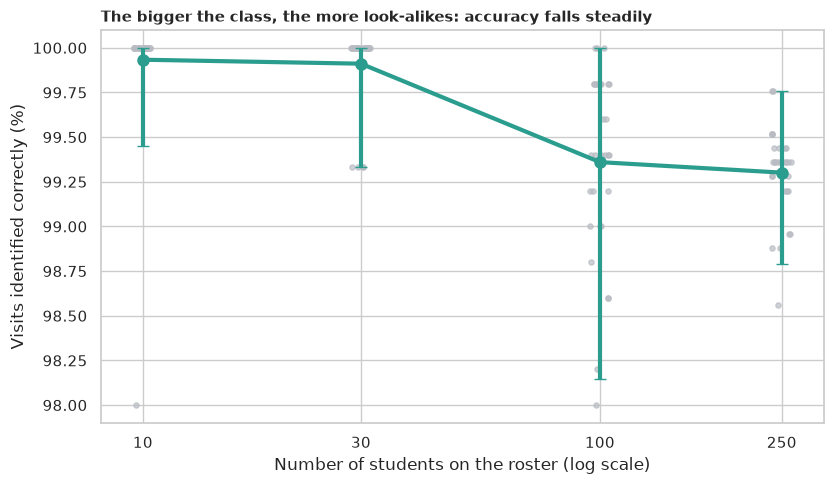

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for n, group in size_table.groupby("students"):
    ax.scatter(
        np.full(len(group), n) * rng.uniform(0.95, 1.05, len(group)),
        group["accuracy"] * 100,
        s=14,
        color=GREY,
        alpha=0.7,
    )
ax.errorbar(
    summary.index,
    summary["mean"] * 100,
    color=TEAL,
    lw=3,
    marker="o",
    ms=8,
    yerr=[(summary["mean"] - summary["low"]) * 100, (summary["high"] - summary["mean"]) * 100],
    capsize=4,
)
ax.set_xscale("log")
ax.set_xticks(SIZES, [str(s) for s in SIZES])
ax.set_xlabel("Number of students on the roster (log scale)")
ax.set_ylabel("Visits identified correctly (%)")
ax.set_title(
    "The bigger the class, the more look-alikes: accuracy falls steadily",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_roster_size.png", dpi=150)
plt.show()

**How to read this:**

- **Accuracy falls slowly as the class grows:** **99.93%** with 10 students, **99.91%** with 30, **99.36%** with 100 and **99.30%** with 250. The spread over random rosters is small (at 100 students from **98.0%** to **100%**).
- **The effect is real but small:** the Kruskal-Wallis test gives p = 1e-15, and each tenfold increase in roster size lowers the accuracy by **0.5 points** (95% CI 0.4 to 0.7; p = 6e-13). **We reject H₀.**
- **But this is a gentle test:** all students are public figures with many good photographs, nobody has an identical twin in the class, and the visitors are told to be students. The next sections remove those comforts.

## 7. H2: do more enrolment photographs help?

*What:* the same 30 rosters of 100 students, enrolled with **1, 3 or 5** photographs (the template is their average description), judged on the same visits. We compare the settings pair by pair across the 30 rosters. *Why:* each extra photograph is work for the student and the teacher; is it worth it?

In [6]:
rows = []
for n_enrol in (1, 3, 5):
    for draw in range(N_DRAWS):
        gen = np.random.default_rng([SEED, 100, draw])  # the same 30 rosters for every setting
        roster = draw_roster(100, n_enrol, gen)
        pred, _ = identify(roster, roster["visits"])
        rows.append(
            {"photos": n_enrol, "draw": draw, "accuracy": float((pred == roster["owner"]).mean())}
        )
enrol_table = pd.DataFrame(rows)
wide = enrol_table.pivot(index="draw", columns="photos", values="accuracy")
print("Closed-set accuracy with 100 students, by number of enrolment photographs:")
print(wide.agg(["mean", "std", "min", "max"]).round(4).to_string())
for a, b in ((1, 3), (3, 5), (1, 5)):
    wil = stats.wilcoxon(wide[b], wide[a])
    print(
        f"{b} photographs minus {a}: {(wide[b] - wide[a]).mean() * 100:+.1f} points; better in "
        f"{int((wide[b] > wide[a]).sum())} of {N_DRAWS} rosters; paired Wilcoxon p = "
        f"{fmt_p(wil.pvalue)}"
    )

Closed-set accuracy with 100 students, by number of enrolment photographs:
photos       1       3       5
mean    0.9936  0.9989  0.9993
std     0.0053  0.0017  0.0012
min     0.9800  0.9935  0.9970
max     1.0000  1.0000  1.0000
3 photographs minus 1: +0.5 points; better in 25 of 30 rosters; paired Wilcoxon p = 7.6e-06
5 photographs minus 3: +0.0 points; better in 9 of 30 rosters; paired Wilcoxon p = 5.3e-01
5 photographs minus 1: +0.6 points; better in 24 of 30 rosters; paired Wilcoxon p = 2.0e-05


**How to read this:**

- **A second and third photograph help a little:** accuracy rises from **99.36%** (1 photograph) to **99.89%** (3 photographs): **+0.5 points**, better in **25 of 30** rosters (paired Wilcoxon p = 8e-6). **We reject H₀.**
- **Beyond three it stops:** 5 photographs give **99.93%**, +0.04 points over 3 (better in 9 of 30 rosters, p = 0.53). Averaging three descriptions already smooths out the pose and expression of any one photograph.
- **The practical rule:** enrol each student with about three varied photographs.

## 8. H3: what about strangers?

*What:* an **open-set** test, the situation of a real classroom: **guests who are not on the roster** walk in. Each visit (a student or a guest) is matched to the nearest student, and accepted only if the cosine similarity is at least a **threshold**. We count, for 100-student rosters with one enrolment photograph, the share of student visits **identified** (accepted and named correctly), the share accepted with the **wrong name**, and the share of **guest** visits accepted (the false accept rate). We compare three rules: no threshold at all (the legacy behaviour in spirit: the nearest student is always taken), the model's recommended threshold (0.363), and a threshold **chosen on 30 other rosters to let in at most 1% of the guests**, judged on 30 new rosters. *Why:* the register's worst mistake is marking an absent student present because a stranger looked a bit like them.

In [7]:
TAUS = np.round(np.arange(0.0, 0.801, 0.01), 2)


def open_set_curves(n: int, n_enrol: int, draws: range, scale: float = 1.0) -> pd.DataFrame:
    """Identification rate and false-accept rate as the acceptance threshold changes.

    A student visit counts as *identified* if it is accepted and the nearest student is the right
    one; a guest visit is a *false accept* if it is accepted (as anyone). Photographs without a
    detected face are never accepted.

    Args:
        n: Students on the roster.
        n_enrol: Enrolment photographs per student.
        draws: Which random rosters to use.
        scale: Which version (distance) of the visit photographs to use.

    Returns:
        One row per threshold, averaged over the rosters.
    """
    rows = []
    for draw in draws:
        gen = np.random.default_rng([SEED, 7, n, draw])
        roster = draw_roster(n, n_enrol, gen)
        pred, sim = identify(roster, roster["visits"], scale)
        guests = guest_photographs(roster, len(roster["visits"]), gen)
        _, guest_sim = identify(roster, guests, scale)
        right = pred == roster["owner"]
        for t in TAUS:
            rows.append(
                {
                    "draw": draw,
                    "threshold": t,
                    "identified": float(((sim >= t) & right).mean()),
                    "wrong name": float(((sim >= t) & ~right).mean()),
                    "false accept": float((guest_sim >= t).mean()),
                }
            )
    return pd.DataFrame(rows)


calibration = open_set_curves(100, 1, range(1000, 1000 + N_DRAWS))
test_curves = open_set_curves(100, 1, range(N_DRAWS))
cal = calibration.groupby("threshold")[["identified", "wrong name", "false accept"]].mean()
tuned_tau = float(cal[cal["false accept"] <= 0.01].index.min())
test = test_curves.groupby("threshold")[["identified", "wrong name", "false accept"]].mean()
print(
    f"Threshold chosen on {N_DRAWS} calibration rosters so that at most 1% of guests are "
    f"accepted: {tuned_tau:.2f} (the recommended fixed value is {SFACE_THRESHOLD})"
)
for name, t in [
    ("fixed (recommended)", SFACE_THRESHOLD),
    ("tuned for 1% false accepts", tuned_tau),
]:
    row = test_curves[np.isclose(test_curves["threshold"], round(t, 2))]
    parts = []
    for column in ("identified", "wrong name", "false accept"):
        values = row[column].to_numpy()
        parts.append(
            f"{column} {values.mean():.1%} (range {values.min():.1%} to {values.max():.1%})"
        )
    print(f"On {N_DRAWS} new rosters, threshold {name} {t:.2f}: " + "; ".join(parts))
none = test.loc[0.0]
print(
    f"With no threshold at all (always accept the nearest student): "
    f"{none['identified']:.1%} identified, {none['wrong name']:.1%} wrong names, "
    f"{none['false accept']:.0%} of the guests accepted"
)

Threshold chosen on 30 calibration rosters so that at most 1% of guests are accepted: 0.44 (the recommended fixed value is 0.363)
On 30 new rosters, threshold fixed (recommended) 0.36: identified 98.8% (range 97.4% to 99.4%); wrong name 0.1% (range 0.0% to 0.6%); false accept 11.8% (range 7.0% to 16.4%)
On 30 new rosters, threshold tuned for 1% false accepts 0.44: identified 96.1% (range 93.8% to 98.2%); wrong name 0.0% (range 0.0% to 0.2%); false accept 0.9% (range 0.0% to 3.0%)
With no threshold at all (always accept the nearest student): 99.5% identified, 0.5% wrong names, 100% of the guests accepted


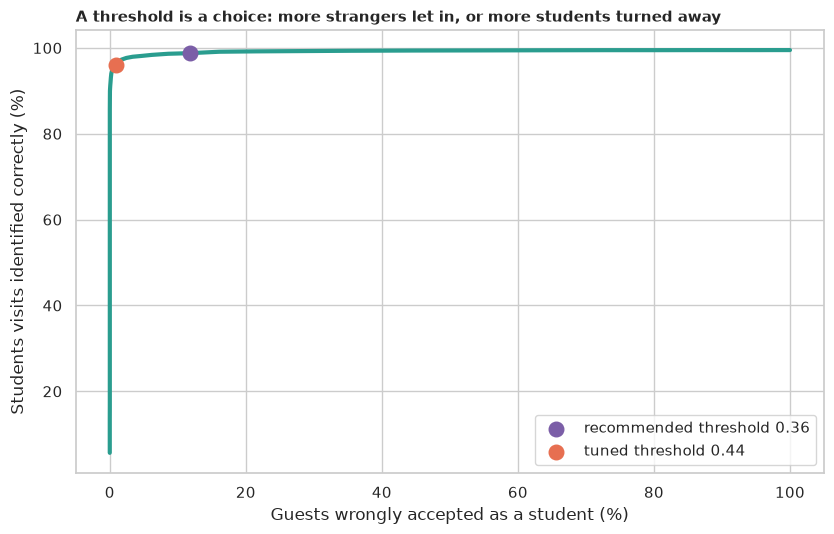

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(test["false accept"] * 100, test["identified"] * 100, color=TEAL, lw=3)
for name, t, color in [("recommended", SFACE_THRESHOLD, PURPLE), ("tuned", tuned_tau, ORANGE)]:
    row = test.loc[round(t, 2)]
    ax.scatter(
        row["false accept"] * 100,
        row["identified"] * 100,
        s=110,
        color=color,
        zorder=3,
        label=f"{name} threshold {t:.2f}",
    )
ax.set_xlabel("Guests wrongly accepted as a student (%)")
ax.set_ylabel("Students visits identified correctly (%)")
ax.set_title(
    "A threshold is a choice: more strangers let in, or more students turned away",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_open_set.png", dpi=150)
plt.show()

**How to read this:**

- **With no threshold every stranger is accepted:** 99.5% of the students are named correctly, but **100%** of the guests are accepted as somebody. A register that always picks the nearest student cannot say "I don't know you".
- **The recommended threshold is too lenient for a roster:** at 0.363, **98.8%** of student visits are identified but **11.8%** of the guests are accepted (range over rosters 7.0% to 16.4%). The threshold was designed for comparing *two* photographs, where it lets in 0.07% of strangers; against **100** students a stranger gets 100 chances to look like one of them, so the false accept rate is more than a hundred times larger.
- **A threshold tuned to the roster fixes it:** chosen on calibration rosters, the threshold is **0.44**. On new rosters it accepts **0.9%** of the guests (range 0.0% to 3.0%) and still identifies **96.1%** of the student visits (93.8% to 98.2%). The price of keeping strangers out is turning away about 3 in 100 genuine visits.
- **Misnamed students are rare** (0.1% at 0.363, 0.0% at 0.44): the errors are mostly "accepted a stranger" or "rejected a student", not "named the wrong student". **We reject H₀.**

## 9. H4: what does standing further back cost?

*What:* repeat the open-set test at the three scales: students and guests photographed at full size (a face of about 93 pixels), half size (48 pixels) and quarter size (24 pixels), with students enrolled from the full-size photographs and the threshold fixed at the tuned value. We compare identification at full and quarter size with a paired Wilcoxon test across the 30 rosters. *Why:* the legacy script shrinks every frame to a quarter before looking for faces; this is what that does.

In [9]:
rows = []
for scale in SCALES:
    curves = open_set_curves(100, 1, range(N_DRAWS), scale)
    mean = curves.groupby("threshold")[["identified", "wrong name", "false accept"]].mean()
    at_tuned = curves[np.isclose(curves["threshold"], round(tuned_tau, 2))]
    seen = ~np.isnan(embeddings[scale][:, 0])
    rows.append(
        {
            "scale": scale,
            "face found": seen.mean(),
            "median face width (px)": np.median(widths[scale][seen]),
            "closest-student accuracy": mean.loc[0.0, "identified"],
            "identified at the tuned threshold": at_tuned["identified"].mean(),
            "guests accepted at the tuned threshold": at_tuned["false accept"].mean(),
        }
    )
distance = pd.DataFrame(rows).set_index("scale")
print(distance.round(3).to_string())
close, far = (
    curves
    for curves in (
        open_set_curves(100, 1, range(N_DRAWS), 1.0),
        open_set_curves(100, 1, range(N_DRAWS), 0.25),
    )
)
a = close[np.isclose(close["threshold"], round(tuned_tau, 2))]["identified"].to_numpy()
b = far[np.isclose(far["threshold"], round(tuned_tau, 2))]["identified"].to_numpy()
wil = stats.wilcoxon(a, b)
print(
    f"Identified at the tuned threshold, full size minus quarter size: {(a - b).mean() * 100:+.1f} "
    f"points; better in {int((a > b).sum())} of {N_DRAWS} rosters; paired Wilcoxon p = "
    f"{fmt_p(wil.pvalue)}"
)

       face found  median face width (px)  closest-student accuracy  identified at the tuned threshold  guests accepted at the tuned threshold
scale                                                                                                                                         
1.00        1.000                  92.784                     0.995                              0.961                                   0.009
0.50        1.000                  47.577                     0.994                              0.959                                   0.008
0.25        0.999                  24.265                     0.975                              0.853                                   0.004


Identified at the tuned threshold, full size minus quarter size: +10.7 points; better in 30 of 30 rosters; paired Wilcoxon p = 1.7e-06


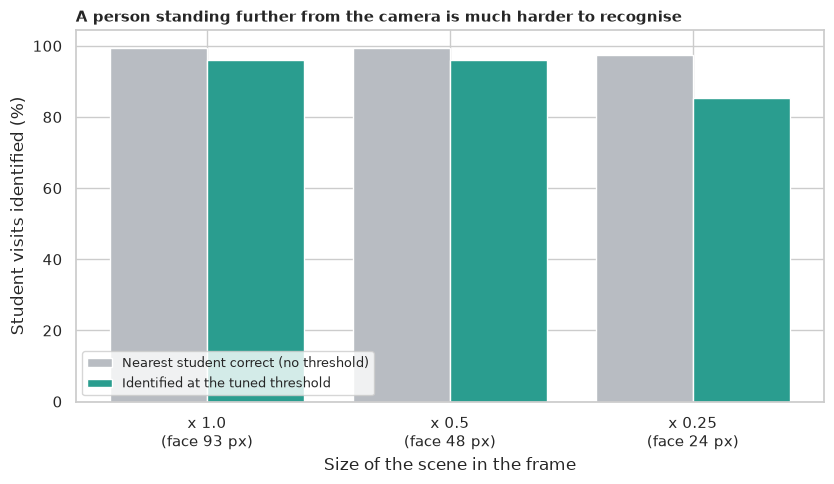

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.arange(len(SCALES))
ax.bar(
    x - 0.2,
    distance["closest-student accuracy"] * 100,
    0.4,
    color=GREY,
    label="Nearest student correct (no threshold)",
)
ax.bar(
    x + 0.2,
    distance["identified at the tuned threshold"] * 100,
    0.4,
    color=TEAL,
    label="Identified at the tuned threshold",
)
ax.set_xticks(
    x,
    [
        f"x {s}\n(face {w:.0f} px)"
        for s, w in zip(SCALES, distance["median face width (px)"], strict=True)
    ],
)
ax.set_xlabel("Size of the scene in the frame")
ax.set_ylabel("Student visits identified (%)")
ax.set_title(
    "A person standing further from the camera is much harder to recognise",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_distance.png", dpi=150)
plt.show()

**How to read this:**

- **Half size costs almost nothing:** identification at the tuned threshold is **95.9%** (against **96.1%** at full size) and the guests accepted stay at **0.8%**.
- **Quarter size costs a lot:** identification falls to **85.3%**, a drop of **10.7 points** (30 of 30 rosters, paired Wilcoxon p = 2e-6), even though a face is still found in **99.9%** of the photographs. The nearest-student accuracy with no threshold falls less (99.5% to 97.5%), but the similarities themselves fall, so many genuine visits drop below the threshold. **We reject H₀.**
- **The lesson for the legacy script:** shrinking frames by 4 before detection speeds it up but throws away the detail the recogniser needs; keep the faces at 50 pixels or more.

## 10. H5: the attendance sheet

*What:* a simulation of a whole class. In each of **300 sessions** a roster of **30 students** (each enrolled with 3 photographs) is drawn; **24 of them come** and **5 guests** who are not on the roster also walk in; every visitor is photographed **3 times** (3 different photographs). Two rules fill the register: **A (legacy-style):** each frame is matched to the nearest student and accepted if above the recommended threshold (0.363); a student is marked present if **any** frame is accepted for them. **B (tuned):** the threshold tuned in H3 (0.44) and a student is marked only if **at least 2 of 3 frames** agree on them. We count the students marked correctly, the **absent students marked present** (the wrong entries) and the sessions with at least one wrong entry. *Why:* this is the register itself, the thing the system is for.

In [11]:
def run_session(gen: np.random.Generator, tau_fixed: float, tau_tuned: float) -> dict:
    """One simulated class: who is marked present on the attendance sheet, under two rules.

    A class of 30 students (3 enrolment photographs each) is visited by 24 of them and by 5 guests
    who are not on the roster; each visitor is photographed 3 times. Rule A is the legacy one:
    each frame is matched to the nearest student and accepted above ``tau_fixed``; a student is
    marked present if any frame is accepted for them. Rule B accepts a frame above ``tau_tuned``
    and marks a student only if at least 2 of the 3 frames agree on that student.

    Args:
        gen: Random number generator.
        tau_fixed: Threshold of rule A.
        tau_tuned: Threshold of rule B.

    Returns:
        The sheet errors of each rule for this session.
    """
    chosen = gen.choice(len(eligible), 30, replace=False)
    templates, frames = [], {}
    present = set(gen.choice(30, 24, replace=False).tolist())
    for k, person in enumerate(chosen):
        idx = gen.permutation(by_person[eligible[person]])
        enrol = embeddings[1.0][idx[:3]]
        enrol = enrol[~np.isnan(enrol[:, 0])]
        template = enrol.mean(0) if len(enrol) else np.zeros(128, np.float32)
        templates.append(template / (np.linalg.norm(template) + 1e-9))
        frames[k] = idx[3:6]
    templates = np.stack(templates)
    visitors = [(k, frames[k]) for k in sorted(present)]
    names = {eligible[p] for p in chosen}
    pool = np.flatnonzero(~np.isin(owner, list(names)))
    guest_people = gen.choice(len(pool), 5, replace=False)
    visitors += [(-1 - g, gen.choice(pool, 3, replace=False)) for g in range(len(guest_people))]
    out = {}
    for rule, tau, need in (("A", tau_fixed, 1), ("B", tau_tuned, 2)):
        marked = set()
        for _, rows in visitors:
            sims = np.nan_to_num(embeddings[1.0][rows] @ templates.T, nan=-1.0)
            votes = [int(sims[i].argmax()) for i in range(len(rows)) if sims[i].max() >= tau]
            for student in set(votes):
                if votes.count(student) >= need:
                    marked.add(student)
        out[rule] = {
            "present students marked": len(marked & present) / len(present),
            "absent students marked": len(marked - present),
            "marks on the sheet": len(marked),
        }
    return out


tau_pair = (SFACE_THRESHOLD, tuned_tau)
sessions = [run_session(np.random.default_rng([SEED, 99, s]), *tau_pair) for s in range(N_SESSIONS)]
rows = []
for rule, label in (
    ("A", f"Legacy-style: nearest student, threshold {tau_pair[0]:.2f}, any 1 frame"),
    ("B", f"Tuned: threshold {tau_pair[1]:.2f}, 2 of 3 frames agree"),
):
    table = pd.DataFrame([s[rule] for s in sessions])
    rows.append(
        {
            "rule": label,
            "present students marked": table["present students marked"].mean(),
            "absent students marked": table["absent students marked"].mean(),
            "sessions with a false mark": (table["absent students marked"] > 0).mean(),
        }
    )
sheet = pd.DataFrame(rows).set_index("rule")
print(f"{N_SESSIONS} simulated classes (30 students, 24 present, 5 guests, 3 frames per visitor):")
print(sheet.round(3).to_string())
for column in ("present students marked", "absent students marked"):
    a = np.array([s["A"][column] for s in sessions])
    b = np.array([s["B"][column] for s in sessions])
    nonzero = a != b
    wil = stats.wilcoxon(b[nonzero], a[nonzero]) if nonzero.any() else None
    print(
        f"{column}: tuned minus legacy-style {np.mean(b - a):+.3f} per session; better or equal "
        f"in {np.mean(b >= a) if column.startswith('present') else np.mean(b <= a):.0%} of "
        f"sessions; paired Wilcoxon p = {fmt_p(wil.pvalue) if wil else 'n/a'}"
    )

300 simulated classes (30 students, 24 present, 5 guests, 3 frames per visitor):
                                                            present students marked  absent students marked  sessions with a false mark
rule                                                                                                                                   
Legacy-style: nearest student, threshold 0.36, any 1 frame                      1.0                   0.187                       0.163
Tuned: threshold 0.44, 2 of 3 frames agree                                      1.0                   0.000                       0.000
present students marked: tuned minus legacy-style +0.000 per session; better or equal in 100% of sessions; paired Wilcoxon p = n/a
absent students marked: tuned minus legacy-style -0.187 per session; better or equal in 100% of sessions; paired Wilcoxon p = 3.6e-11


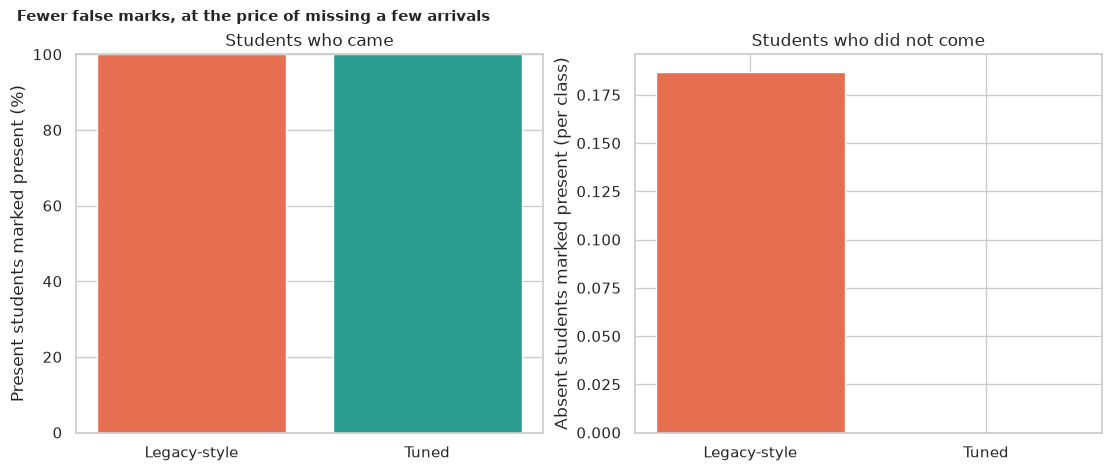

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
colors = [ORANGE, TEAL]
labels = ["Legacy-style", "Tuned"]
axes[0].bar(labels, sheet["present students marked"] * 100, color=colors)
axes[0].set_ylabel("Present students marked present (%)")
axes[0].set_ylim(0, 100)
axes[0].set_title("Students who came")
axes[1].bar(labels, sheet["absent students marked"], color=colors)
axes[1].set_ylabel("Absent students marked present (per class)")
axes[1].set_title("Students who did not come")
fig.suptitle(
    "Fewer false marks, at the price of missing a few arrivals",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "04_sheet.png", dpi=150)
plt.show()

**How to read this:**

- **Both rules mark the students who came:** in both, **100%** of the present students are marked (to three decimals); a student who is photographed three times is rarely missed.
- **The legacy-style rule writes wrong entries:** it marks on average **0.19 absent students per class**, and **16.3%** of the sessions have at least one wrong entry (a stranger or a similar-looking student taken for an absent one).
- **The tuned rule writes none:** **0.000** absent students marked in the 300 sessions (**0%** of sessions with a wrong entry), with no loss in the students marked. The difference in wrong entries per session is **-0.19** (paired Wilcoxon p = 4e-11): the careful rule is never worse than the legacy one. **We reject H₀.**
- **Caveat:** guests are drawn at random from thousands of people, so none of them is a deliberate impostor or a twin; a real class has more look-alikes (relatives, friends) than this simulation.

## 11. 🎯 Takeaways

1. **Class size matters, gently:** nearest-student accuracy falls from 99.9% (10 students) to 99.3% (250), about 0.5 points per tenfold, on these easy photographs.
2. **Three enrolment photographs are enough:** +0.5 points over one (25 of 30 rosters), no gain from a fifth.
3. **A register must be able to say "I don't know you":** with no threshold, 100% of guests are accepted; with the recommended pairwise threshold 11.8% still are, because a stranger is compared with the whole class. A threshold tuned on the roster size lets in 0.9% and costs about 3 points of identification.
4. **Do not shrink the frame by 4:** at a quarter size (a face of 24 pixels) identification falls by 10.7 points, though a face is still found.
5. **Look twice:** requiring 2 of 3 frames and a tuned threshold removed every wrong entry in 300 simulated classes (against 0.19 per class and 16% of sessions for the legacy rule), without missing any student who came.
6. **A register's metric is its wrong entries, not its accuracy:** the headline accuracy of 99%+ hides the 16% of classes that contain a wrong mark.

## 12. ⚠️ Limitations

- **LFW is not a classroom:** public figures photographed by news agencies, not students on a webcam; accuracy in a real class will be lower.
- **The roster is drawn from the 311 most photographed people,** so every student has good, varied photographs for enrolment and visits.
- **Guests are random strangers,** not look-alikes, relatives or impostors; a real register faces harder cases.
- **Distance is simulated** by shrinking the photograph; a real camera at a distance also changes focus, noise and angle.
- **Three random frames per visitor are three different photographs,** not three consecutive video frames, so they are less alike than real frames would be.
- **No spoofing:** a printed photograph or a video would be accepted as the person.
- **No demographic analysis:** LFW is unbalanced and has no group labels, so differences in error rates across groups were not measured.
- **Thresholds were tuned for one setting** (100 students, one enrolment photograph, 1% false accepts) and used elsewhere (30 students, three photographs).
- **Taking attendance by face is a privacy decision** as well as a technical one: it needs the students' consent and a secure way to store their faces.